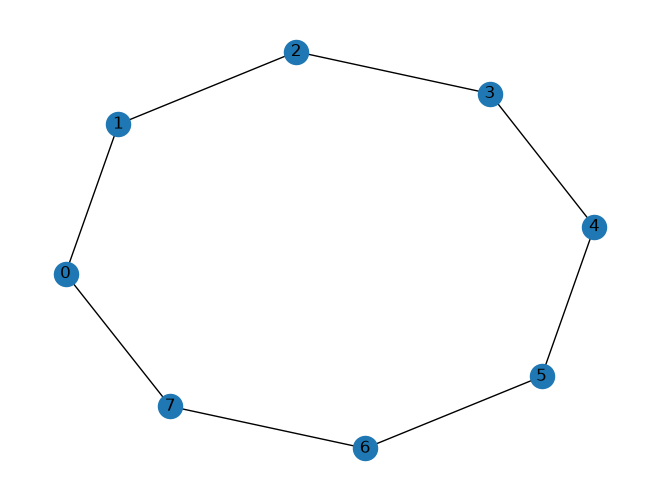

In [13]:
import networkx as nx
import matplotlib.pyplot as plt
from src.graphs import make_ring, make_grid, make_regular3, make_random, make_complete

# graf inel
graph = make_ring(8)
nx.draw(graph, with_labels=True)


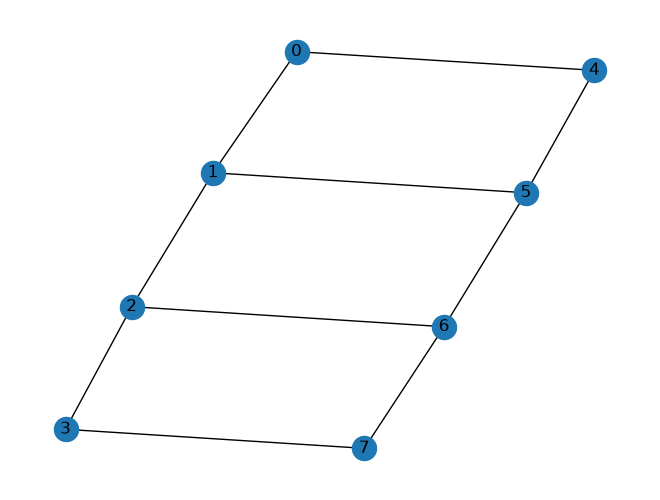

In [14]:
# graf grid
graph = make_grid(2, 4)
nx.draw(graph, with_labels=True)

[(0, 7), (0, 3), (0, 5), (1, 2), (1, 5), (1, 3), (2, 4), (2, 3), (4, 6), (4, 7), (5, 6), (6, 7)]


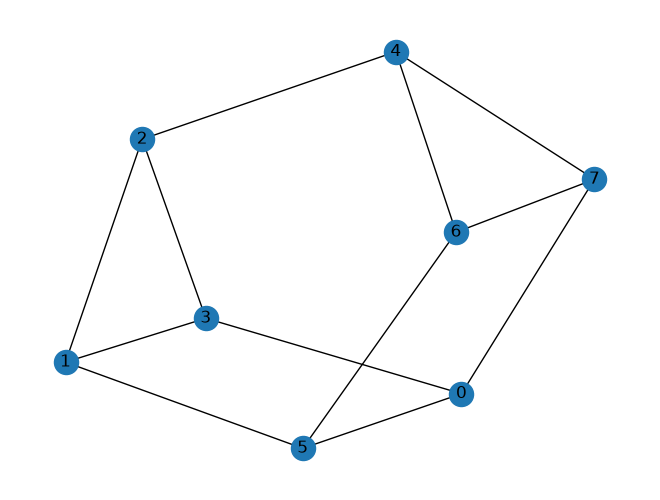

In [15]:
# graf regular3
graph = make_regular3(8, 20)
print(graph.edges())
nx.draw(graph, with_labels=True)

In [16]:
from src.classical import cut_value, bisection_bruteforce
from src.graphs import make_ring, make_complete
import networkx as nx

triangle = nx.Graph([(0, 1), (0, 2), (1, 2)])
assert cut_value(triangle, "001") == 2

ring = make_ring(6)
assert cut_value(ring, "000111") == 2

complete = make_complete(4)
assert cut_value(complete, "0011") == 4
# result = bisection_bruteforce(make_complete(6))
# print(result)

star = nx.Graph([(0, 1), (0, 2)])
assert cut_value(star, "001") == 2

In [17]:
from src.classical import max_cut_bruteforce, bisection_bruteforce
# Max-Cut on the triangle: best cut is 2, reached by 6 bitstrings
value, optimal = max_cut_bruteforce(triangle)
assert value == 2 and len(optimal) == 6

# Max-Cut on the ring of 6: alternate the machines, every edge is cut
value, optimal = max_cut_bruteforce(make_ring(6))
assert value == 6 and sorted(optimal) == ["010101", "101010"]

# Bisection on the ring of 6: cut into two arcs of 3, 6 ways to choose the arc
value, optimal = bisection_bruteforce(make_ring(6))
assert value == 2 and len(optimal) == 6

# Bisection on the complete graph of 6: every balanced split costs (6/2)^2 = 9
value, optimal = bisection_bruteforce(make_complete(6))
assert value == 9 and len(optimal) == 20

In [18]:
%load_ext autoreload
%autoreload 2

import pandas as pd
from src.graphs import load_instances, json_to_graph, find_instance
from src.classical import (
    bisection_bruteforce, max_cut_bruteforce,
    bisection_greedy, max_cut_greedy,
    bisection_random_stats, max_cut_random_stats,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [19]:
instances = load_instances("../data/instances.json")
print(len(instances), "instances")

25 instances


In [20]:
rows = []

for instance in instances:
    graph = json_to_graph(instance)

    # bisection
    optimum, optimal_bitstrings = bisection_bruteforce(graph)
    greedy_cost, _ = bisection_greedy(graph)
    random_mean, random_std = bisection_random_stats(graph)

    row = {
        "name": instance["name"],
        "graph_type": instance["graph_type"],
        "n": instance["n"],
        "num_edges": graph.number_of_edges(),
        "problem": "bisection",
        "optimum": optimum,
        "num_optima": len(optimal_bitstrings),
        "greedy": greedy_cost,
        "random_mean": random_mean,
        "random_std": random_std,
    }
    rows.append(row)

    # max-cut
    optimum, optimal_bitstrings = max_cut_bruteforce(graph)
    greedy_cost, _ = max_cut_greedy(graph)
    random_mean, random_std = max_cut_random_stats(graph)

    row = {
        "name": instance["name"],
        "graph_type": instance["graph_type"],
        "n": instance["n"],
        "num_edges": graph.number_of_edges(),
        "problem": "maxcut",
        "optimum": optimum,
        "num_optima": len(optimal_bitstrings),
        "greedy": greedy_cost,
        "random_mean": random_mean,
        "random_std": random_std,
    }
    rows.append(row)

In [21]:
table = pd.DataFrame(rows)
table

,name,graph_type,n,num_edges,problem,optimum,num_optima,greedy,random_mean,random_std
0,ring_6,ring,6,6,bisection,2,6,2,3.600000,1.200000
1,ring_6,ring,6,6,maxcut,6,2,6,3.000000,1.224745
2,grid_6,grid,6,7,bisection,3,6,3,4.200000,1.166190
3,grid_6,grid,6,7,maxcut,7,2,7,3.500000,1.322876
4,regular3_6,regular3,6,9,bisection,3,2,3,5.400000,1.200000
5,regular3_6,regular3,6,9,maxcut,7,6,7,4.500000,1.500000
6,random_6,random,6,8,bisection,4,8,4,4.800000,0.748331
7,random_6,random,6,8,maxcut,6,6,6,4.000000,1.414214
8,complete_6,complete,6,15,bisection,9,20,9,9.000000,0.000000
9,complete_6,complete,6,15,maxcut,9,20,9,7.500000,1.936492


In [22]:
table.to_csv("../data/reference.csv", index=False)

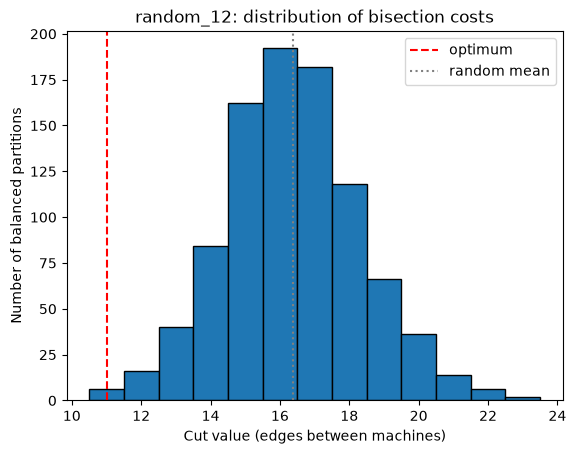

In [23]:
import matplotlib.pyplot as plt
import numpy as np
from src.classical import bisection_all_costs

instance = find_instance(instances, "random_12")   # choose one, e.g. find "random_12" in the list
graph = json_to_graph(instance)

costs = bisection_all_costs(graph)
optimum, _ = bisection_bruteforce(graph)
mean = np.mean(costs)

# one bar for every integer cost
bins = range(min(costs), max(costs) + 2)
plt.hist(costs, bins=bins, align="left", edgecolor="black")

# reference lines
plt.axvline(optimum, color="red", linestyle="--", label="optimum")
plt.axvline(mean, color="gray", linestyle=":", label="random mean")

# labels
plt.xlabel("Cut value (edges between machines)")
plt.ylabel("Number of balanced partitions")
plt.title(instance["name"] + ": distribution of bisection costs")
plt.legend()

plt.savefig("../figures/costs_" + instance["name"] + ".png", dpi=150)
plt.show()